# 01 — Análise Exploratória de Dados

Toda visualização é seguida por uma interpretação objetiva. As bases são exploradas no estado bruto; a definição formal do target é consolidada no notebook 02.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import RANDOM_STATE, FIGURES, METRICS, MODELS, TARGET

FIGURES.mkdir(parents=True, exist_ok=True)
METRICS.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
print("RANDOM_STATE =", RANDOM_STATE)

from src.data import load_raw
from src.preprocessing import build_target

RANDOM_STATE = 42


In [2]:
application, credit = load_raw()
print("application_record:", application.shape)
print("credit_record:", credit.shape)
display(application.head())
display(credit.head())

application_record: (438557, 18)
credit_record: (1048575, 3)


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0


,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,C


## 1. Visão geral

Dimensões, tipos, identificadores, ausências e primeira impressão das duas bases.

In [3]:
print("APPLICATION_RECORD")
application.info()
print("\nCREDIT_RECORD")
credit.info()
resumo_bases = pd.DataFrame({
    "base": ["application_record", "credit_record"],
    "linhas": [len(application), len(credit)],
    "colunas": [application.shape[1], credit.shape[1]],
    "ids_unicos": [application["ID"].nunique(), credit["ID"].nunique()],
    "ids_duplicados": [application.duplicated("ID").sum(), credit.duplicated("ID").sum()],
})
display(resumo_bases)
nulos_application = pd.DataFrame({"nulos": application.isna().sum(), "pct": (application.isna().mean()*100).round(2)}).query("nulos > 0").sort_values("pct", ascending=False)
display(nulos_application)

APPLICATION_RECORD
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  object 
 2   FLAG_OWN_CAR         438557 non-null  object 
 3   FLAG_OWN_REALTY      438557 non-null  object 
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  object 
 7   NAME_EDUCATION_TYPE  438557 non-null  object 
 8   NAME_FAMILY_STATUS   438557 non-null  object 
 9   NAME_HOUSING_TYPE    438557 non-null  object 
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_MOBIL           438557 non-null  int64  
 13  FLAG_WORK_PHONE      438557 non-null  int64  
 14  FLAG_PHONE           438557 non-null  int64  
 15

,base,linhas,colunas,ids_unicos,ids_duplicados
0,application_record,438557,18,438510,47
1,credit_record,1048575,3,45985,1002590


,nulos,pct
OCCUPATION_TYPE,134203,30.6


**Interpretação.** `application_record` possui 438.557 linhas e 438.510 IDs únicos, portanto existem 47 IDs repetidos. `credit_record` possui 1.048.575 registros mensais referentes a 45.985 clientes. `OCCUPATION_TYPE` concentra as ausências cadastrais relevantes; o notebook 02 trata essa ausência sem excluir clientes.

In [4]:
application_unique, target_eda = build_target(application, credit)
base_eda = (application_unique[application_unique["ID"].isin(target_eda.index)].merge(target_eda,left_on="ID",right_index=True,how="inner").copy())
base_eda["AGE_YEARS"] = -base_eda["DAYS_BIRTH"] / 365.25
base_eda["EMPLOYMENT_YEARS"] = -base_eda["DAYS_EMPLOYED"].replace(365243, np.nan) / 365.25
print("Clientes elegíveis ao target exploratório:", len(base_eda))

Clientes elegíveis ao target exploratório: 33110


## 2. Distribuição das variáveis

As distribuições ajudam a entender escala, assimetria e concentração antes da modelagem.

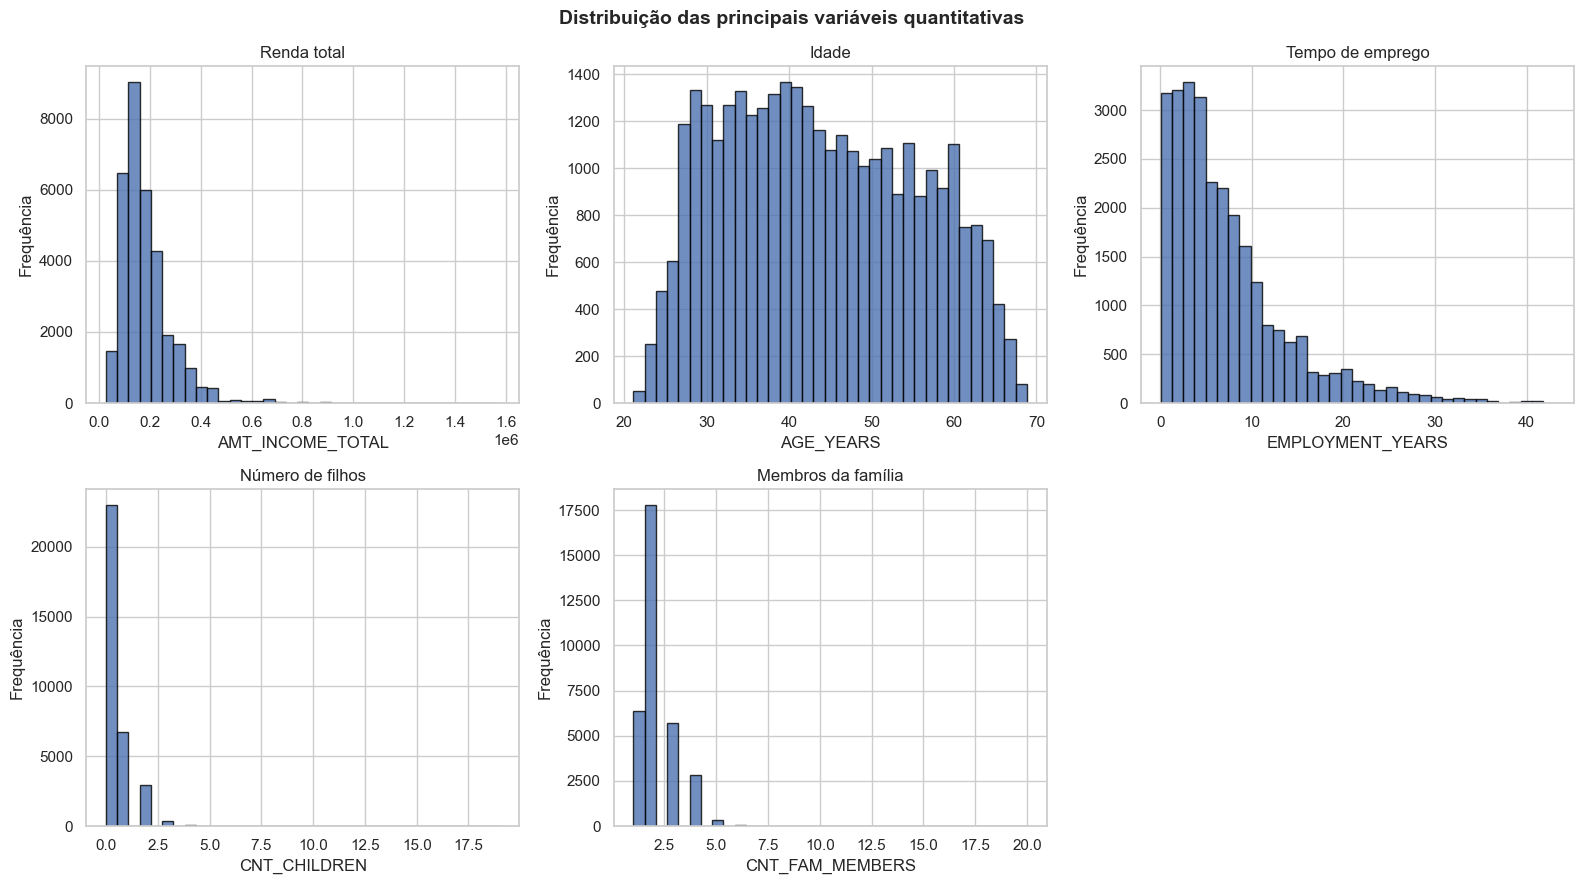

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
variaveis=[("AMT_INCOME_TOTAL","Renda total"),("AGE_YEARS","Idade"),("EMPLOYMENT_YEARS","Tempo de emprego"),("CNT_CHILDREN","Número de filhos"),("CNT_FAM_MEMBERS","Membros da família")]
for ax,(col,titulo) in zip(axes.flat,variaveis):
    ax.hist(base_eda[col].dropna(),bins=35,edgecolor="black",alpha=0.8); ax.set_title(titulo); ax.set_xlabel(col); ax.set_ylabel("Frequência")
axes.flat[-1].axis("off")
plt.suptitle("Distribuição das principais variáveis quantitativas",fontsize=14,fontweight="bold")
plt.tight_layout(); plt.savefig(FIGURES/"01_distribuicoes.png",dpi=160,bbox_inches="tight"); plt.show()

**Interpretação.** Renda e tempo de emprego apresentam assimetria à direita, enquanto idade se distribui de forma mais ampla. As contagens familiares concentram-se em poucos valores. Essas características justificam imputação robusta por mediana e análise explícita dos valores extremos.

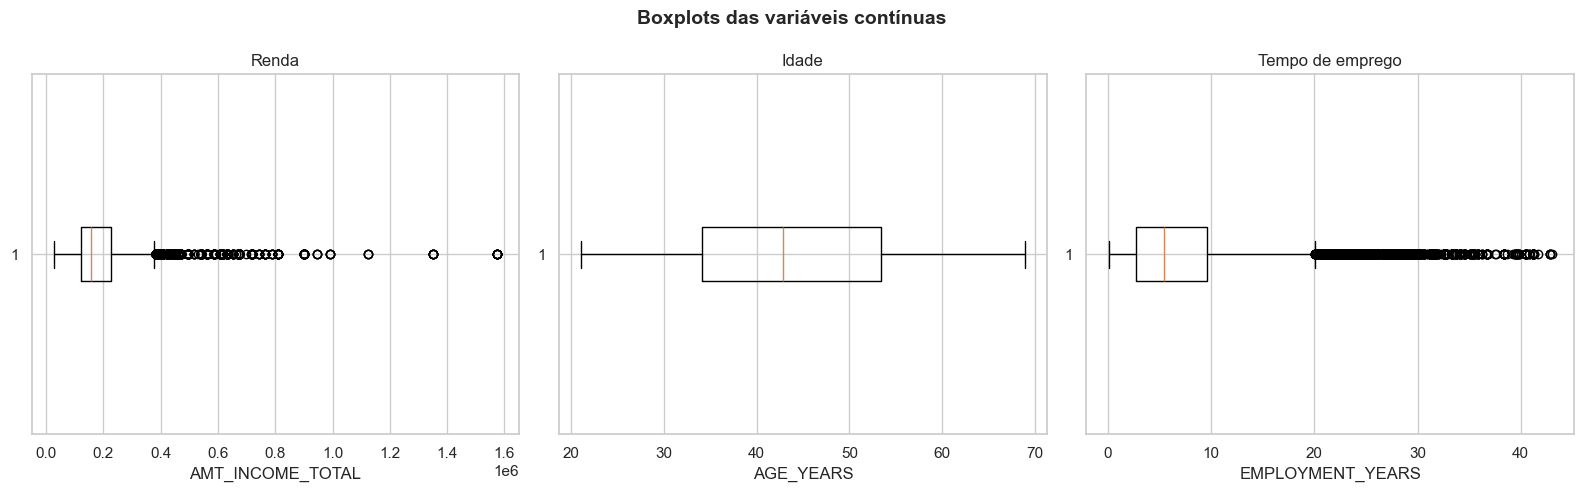

In [6]:
fig, axes = plt.subplots(1,3,figsize=(16,5))
for ax,col,titulo in zip(axes,["AMT_INCOME_TOTAL","AGE_YEARS","EMPLOYMENT_YEARS"],["Renda","Idade","Tempo de emprego"]):
    ax.boxplot(base_eda[col].dropna(),vert=False); ax.set_title(titulo); ax.set_xlabel(col)
plt.suptitle("Boxplots das variáveis contínuas",fontsize=14,fontweight="bold")
plt.tight_layout(); plt.savefig(FIGURES/"02_boxplots.png",dpi=160,bbox_inches="tight"); plt.show()

**Interpretação.** Há valores extremos principalmente em renda e tempo de emprego. Eles não são removidos automaticamente: podem representar clientes legítimos, e árvores são relativamente robustas a extremos. O código especial de emprego é tratado separadamente no notebook 02.

## 3. Correlações

A correlação linear é analisada apenas entre variáveis numéricas.

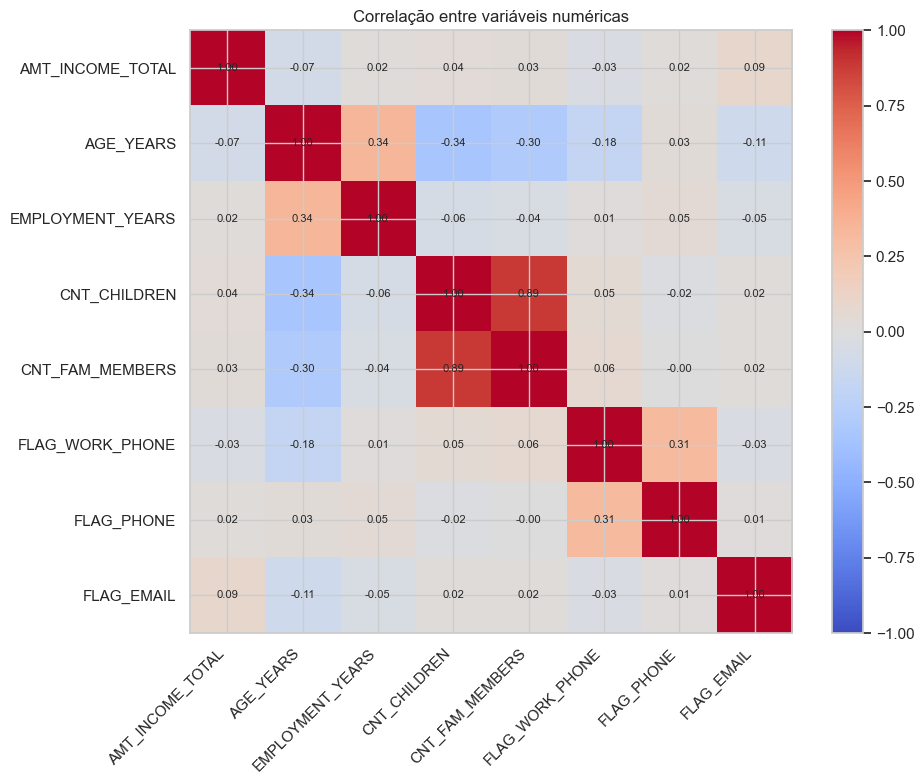

,AMT_INCOME_TOTAL,AGE_YEARS,EMPLOYMENT_YEARS,CNT_CHILDREN,CNT_FAM_MEMBERS,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL
AMT_INCOME_TOTAL,1.00,-0.07,0.02,0.04,0.03,-0.03,0.02,0.09
AGE_YEARS,-0.07,1.00,0.34,-0.34,-0.30,-0.18,0.03,-0.11
EMPLOYMENT_YEARS,0.02,0.34,1.00,-0.06,-0.04,0.01,0.05,-0.05
CNT_CHILDREN,0.04,-0.34,-0.06,1.00,0.89,0.05,-0.02,0.02
CNT_FAM_MEMBERS,0.03,-0.30,-0.04,0.89,1.00,0.06,-0.00,0.02
FLAG_WORK_PHONE,-0.03,-0.18,0.01,0.05,0.06,1.00,0.31,-0.03
FLAG_PHONE,0.02,0.03,0.05,-0.02,-0.00,0.31,1.00,0.01
FLAG_EMAIL,0.09,-0.11,-0.05,0.02,0.02,-0.03,0.01,1.00


In [7]:
cols_corr=["AMT_INCOME_TOTAL","AGE_YEARS","EMPLOYMENT_YEARS","CNT_CHILDREN","CNT_FAM_MEMBERS","FLAG_WORK_PHONE","FLAG_PHONE","FLAG_EMAIL"]
correlacoes=base_eda[cols_corr].corr()
fig,ax=plt.subplots(figsize=(11,8)); im=ax.imshow(correlacoes.values,cmap="coolwarm",vmin=-1,vmax=1)
ax.set_xticks(range(len(cols_corr))); ax.set_yticks(range(len(cols_corr))); ax.set_xticklabels(cols_corr,rotation=45,ha="right"); ax.set_yticklabels(cols_corr)
for i in range(len(cols_corr)):
    for j in range(len(cols_corr)): ax.text(j,i,f"{correlacoes.iloc[i,j]:.2f}",ha="center",va="center",fontsize=8)
fig.colorbar(im,ax=ax,fraction=0.046,pad=0.04); ax.set_title("Correlação entre variáveis numéricas")
plt.tight_layout(); plt.savefig(FIGURES/"03_correlacoes.png",dpi=160,bbox_inches="tight"); plt.show()
display(correlacoes.round(2))

**Interpretação.** A associação mais clara ocorre entre `CNT_CHILDREN` e `CNT_FAM_MEMBERS`, o que é esperado porque filhos compõem o tamanho familiar. Não aparece correlação linear extrema entre renda, idade e tempo de emprego que justifique excluir alguma dessas variáveis. Como a Random Forest captura relações não lineares, correlação baixa não implica irrelevância preditiva.

## 4. Outliers

In [8]:
linhas=[]
for col in ["AMT_INCOME_TOTAL","AGE_YEARS","EMPLOYMENT_YEARS","CNT_CHILDREN","CNT_FAM_MEMBERS"]:
    s=base_eda[col].dropna(); q1,q3=s.quantile([0.25,0.75]); iqr=q3-q1; li=q1-1.5*iqr; ls=q3+1.5*iqr; flag=(s<li)|(s>ls)
    linhas.append({"variavel":col,"limite_inferior":li,"limite_superior":ls,"outliers_iqr":int(flag.sum()),"pct_outliers":round(flag.mean()*100,2)})
tabela_outliers=pd.DataFrame(linhas); display(tabela_outliers)

,variavel,limite_inferior,limite_superior,outliers_iqr,pct_outliers
0,AMT_INCOME_TOTAL,-33750.000000,380250.000000,1342,4.05
1,AGE_YEARS,5.229295,82.261465,0,0.00
2,EMPLOYMENT_YEARS,-7.759069,20.079398,1578,5.74
3,CNT_CHILDREN,-1.500000,2.500000,453,1.37
4,CNT_FAM_MEMBERS,0.500000,4.500000,430,1.30


**Decisão.** Os outliers são mantidos. A regra IQR identifica observações raras, mas não prova erro cadastral. Remover esses clientes sem evidência externa poderia apagar perfis reais. A principal anomalia conhecida (`DAYS_EMPLOYED = 365243`) recebe tratamento específico no notebook 02.

## 5. Balanceamento de classes

,quantidade,percentual
TARGET_BAD,,
0,28819,87.04
1,4291,12.96


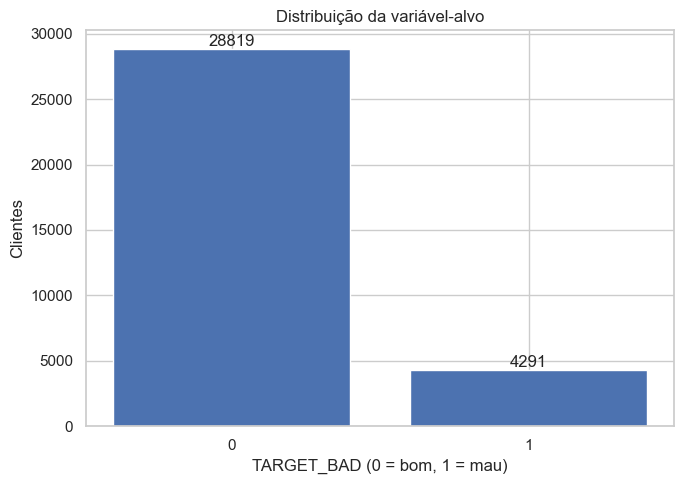

In [9]:
distribuicao_target=pd.DataFrame({"quantidade":base_eda[TARGET].value_counts().sort_index(),"percentual":(base_eda[TARGET].value_counts(normalize=True).sort_index()*100).round(2)})
display(distribuicao_target)
contagens=base_eda[TARGET].value_counts().sort_index(); fig,ax=plt.subplots(figsize=(7,5)); barras=ax.bar([str(i) for i in contagens.index],contagens.values)
ax.set_title("Distribuição da variável-alvo"); ax.set_xlabel("TARGET_BAD (0 = bom, 1 = mau)"); ax.set_ylabel("Clientes"); ax.bar_label(barras)
plt.tight_layout(); plt.savefig(FIGURES/"04_distribuicao_target.png",dpi=160,bbox_inches="tight"); plt.show()

**Interpretação.** A classe positiva representa **12,96%** dos clientes. Acurácia isolada pode ser enganosa, pois um classificador que favoreça a classe majoritária teria alta acurácia e pouco valor para detectar risco. Por isso o projeto prioriza F1, Precision, Recall, ROC-AUC e tipos de erro.

## 6. Síntese da EDA

A EDA mostra uma base fortemente desbalanceada, variáveis numéricas com assimetria e alguns valores extremos, além de ausência concentrada em ocupação e um código especial em tempo de emprego. Nenhum desses pontos justifica exclusão indiscriminada. A estratégia seguinte preserva os clientes, transforma idade e emprego em anos, cria flags de auditoria e mantém imputação/codificação dentro de pipelines para evitar data leakage.